# 001 — Conceptual Track: Intuitive and Visual L1-Native Cohomology
## Sparsity, Discrete Topology, Minimal Representatives, and the Geometry of Obstructions

**Paper Package 002** — *L1-Native Cohomology of Finite Defect Fields*  
**Audience:** Computational scientists, applied mathematicians, graduate students, and educated nonspecialists.  
**AuthorityEffect:** `None`

---

### Core Intuition: Why Difference is Not Defect
When observing measurements across a network (such as flows, voltage drops, velocity fields, or phase differences across edges), we often find discrepancies between adjacent nodes. A fundamental question in discrete geometry is:
> *Can observed edge differences be explained away by adjusting node potentials (a gauge transformation), or is there an irremediable topological obstruction?*

In standard classical mathematics and engineering, one typically performs a **least-squares (L2) projection** (the discrete Hodge-Helmholtz decomposition). However, L2 projection **spreads and smears** localized errors across every single edge in the network.

In this notebook, we explore **L1-native cohomology**. Under the weighted $L^1$ norm, error minimization is governed by the mathematics of linear programming and basis pursuit:
1. **Defect Concentration:** Every quotient class admits an optimal representative concentrated onto a **sparse** subset of edges (at most the cycle rank $\beta$, Theorem L1C-T5: Cycle-Rank Support Bound).
2. **Exact Attainment:** The quotient infimum is always attained by an exact finite minimizer (Theorem L1C-T1).
3. **Dual Circulation Witness:** Every optimal residual is certified by an exact circulation pairing (Theorems L1C-T3, L1C-T4).
4. **Discrete Bianchi Nilpotency:** Pure gauge potentials produce zero field strength ($d_1(d_0 \phi) = 0$, Theorem L1C-T7).
5. **Quantum Phase Cocycles:** Chosen phase lifts, integral-cycle holonomy and static trace-coherence bounds have distinct domains (Theorem L1C-T8).

In [1]:
import sys
from pathlib import Path
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Locate this standalone paper, from its root or notebook directory.
paper_root = Path.cwd()
if paper_root.name == "jupyter_notebooks":
    paper_root = paper_root.parent
found = paper_root / "code"
if not (found / "l1_cohomology.py").is_file():
    raise RuntimeError("Run this notebook from the paper root or jupyter_notebooks directory")
if str(found) not in sys.path:
    sys.path.insert(0, str(found))

from l1_cohomology import (
    DirectedGraph,
    Simplicial2Complex,
    L1QuotientSolver,
    RationalComplex,
    QuantumDensityMatrix,
    ZeroWeightRefusalError,
)

print("[OK] Environment initialized successfully.")
print("[OK] Pure rational L1-cohomology engine imported.")

[OK] Environment initialized successfully.
[OK] Pure rational L1-cohomology engine imported.


## Section 1: Visual Overview & The Cochain Mystery — L1 vs L2 (Hodge) Localization

Consider a finite directed graph with vertices $V$ and edges $E$. 
- A **0-cochain** $f \in C^0 = \mathbb{R}^V$ assigns a scalar value $f(v)$ to each vertex (e.g., node potential, height, temperature).
- A **1-cochain** $\omega \in C^1 = \mathbb{R}^E$ assigns a value $\omega(e)$ to each directed edge (e.g., flow, gradient measurement, phase change).
- The **coboundary operator** $d_0: C^0 \to C^1$ computes the directed difference across each edge:
  $$(d_0 f)(u, v) = f(v) - f(u).$$

A cochain $\omega$ is **exact** (or a coboundary) if $\omega = d_0 f$ for some potential $f$. If $\omega$ is not exact, we seek a potential $f$ that best explains $\omega$, leaving a minimal residual $r = \omega + d_0 f$.

### The Fundamental Difference: L1 vs L2
- **L2 (Least Squares / Hodge):** Solves $\min_f \|\omega + d_0 f\|_2^2$. Because the squared error penalizes large outliers heavily, it distributes residual error smoothly across **every edge** in the network.
- **L1 (Quotient Cohomology):** Solves $\min_f \|\omega + d_0 f\|_{1, \mathbf{w}} = \sum_e w_e |\omega_e + (d_0 f)_e|$. L1 norm minimization acts as an exact $L^1$ filter (basis pursuit), forcing the residual to be **strictly zero** on non-obstructed edges and concentrating the defect onto non-bounding cycles.

Let us test this directly using the counterexample from Section 10 of the paper (also highlighted in Falsifiability):
Consider 3 parallel edges between two vertices $v_0$ and $v_1$ with incidence matrix $\mathbf{B} = (1, 1, 1)^\top$ and observed cochain $\boldsymbol{\omega} = (0, 0, 10)^\top$.

L1 Minimal Representative: r* = [0.0, 0.0, 10.0]
L1 Quotient Norm:          ||r*||_1 = 10.0000
L2 Residual:               r_L2 = [np.float64(-3.3333), np.float64(-3.3333), np.float64(6.6667)]
L2 Residual's L1 norm:     ||r_L2||_1 = 13.3333


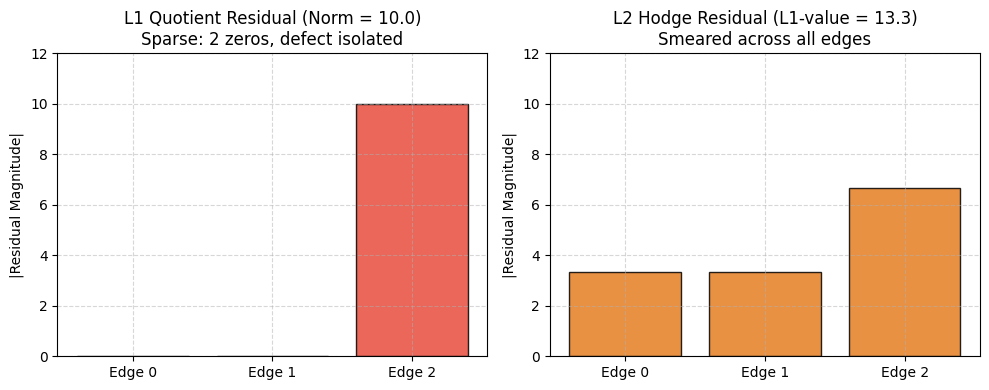

In [2]:
# Section 10 Counterexample: B = (1, 1, 1)^T, omega = (0, 0, 10)^T
# Edges: 3 parallel edges from vertex 0 to vertex 1.
g_counter = DirectedGraph(
    vertices=[0, 1],
    edges=[(0, 1), (0, 1), (0, 1)],
    weights=[1, 1, 1],
    allow_parallel_edges=True
)
omega_counter = [0, 0, 10]

# 1. Exact L1 Quotient Solver
receipt_l1 = L1QuotientSolver.solve(g_counter, omega_counter)
r_l1 = [float(x) for x in receipt_l1.primal_residual]
l1_norm_val = float(receipt_l1.primal_norm)

# 2. L2 Least Squares (Hodge-Helmholtz) Projection
# In L2, we minimize ||omega + B f||_2^2 where f = f(1) - f(0).
# Setting derivative to zero: B^T (omega + B f) = 0 => f = - (B^T B)^{-1} B^T omega
# Here B = [1, 1, 1]^T, so B^T B = 3, B^T omega = 10 => f = -10/3.
# Residual r_L2 = omega + B f = (0 - 10/3, 0 - 10/3, 10 - 10/3) = (-3.333, -3.333, +6.667).
B_mat = np.array([[1.0], [1.0], [1.0]])
omega_np = np.array([0.0, 0.0, 10.0])
f_l2 = -np.linalg.lstsq(B_mat, omega_np, rcond=None)[0]
r_l2 = omega_np + B_mat @ f_l2
l2_as_l1_norm = np.sum(np.abs(r_l2))

print(f"L1 Minimal Representative: r* = {r_l1}")
print(f"L1 Quotient Norm:          ||r*||_1 = {l1_norm_val:.4f}")
print(f"L2 Residual:               r_L2 = {[round(x, 4) for x in r_l2]}")
print(f"L2 Residual's L1 norm:     ||r_L2||_1 = {l2_as_l1_norm:.4f}")

# Plot side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

edges_labels = ["Edge 0", "Edge 1", "Edge 2"]
colors_l1 = ["#2ecc71" if abs(x) < 1e-6 else "#e74c3c" for x in r_l1]
colors_l2 = ["#e67e22" for _ in r_l2]

ax1.bar(edges_labels, np.abs(r_l1), color=colors_l1, alpha=0.85, edgecolor="black")
ax1.set_title(f"L1 Quotient Residual (Norm = {l1_norm_val:.1f})\nSparse: 2 zeros, defect isolated")
ax1.set_ylabel("|Residual Magnitude|")
ax1.set_ylim(0, 12)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.bar(edges_labels, np.abs(r_l2), color=colors_l2, alpha=0.85, edgecolor="black")
ax2.set_title(f"L2 Hodge Residual (L1-value = {l2_as_l1_norm:.1f})\nSmeared across all edges")
ax2.set_ylabel("|Residual Magnitude|")
ax2.set_ylim(0, 12)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Section 2: Discrete Topology & Graphs — Vertices, Edges, and Coboundaries

Let $G = (V, E)$ be a finite directed graph:
- $n = |V|$ vertices and $m = |E|$ edges.
- Edge orientation is bookkeeping: reversing edge $e = (u, v)$ to $(v, u)$ negates its cochain value $\omega(e) \mapsto -\omega(e)$.
- The incidence matrix $\mathbf{B}$ has size $m \times n$:
  $$\mathbf{B}_{e, v} = \begin{cases} +1 & \text{if } v = \text{head}(e), \\ -1 & \text{if } v = \text{tail}(e), \\ 0 & \text{otherwise.} \end{cases}$$
- The coboundary operator is $d_0 f = \mathbf{B} f$.
- The adjoint operator $d_0^* = \mathbf{B}^\top$ is the **divergence operator** mapping edge flows $\mathbf{z}$ to vertex net currents:
  $$(\mathbf{B}^\top \mathbf{z})_v = \sum_{e: \text{head}(e)=v} z_e - \sum_{e: \text{tail}(e)=v} z_e.$$
- A flow $\mathbf{z}$ is a **circulation** if $\mathbf{B}^\top \mathbf{z} = 0$ (divergence-free at every vertex).
- The **cycle rank** (first Betti number) is:
  $$\beta = |E| - |V| + c,$$
  where $c$ is the number of connected components. $\beta$ is the dimension of the quotient cohomology space $Q^1 = C^1 / \text{im } d_0$.

Let us construct and visualize three foundational topologies:
1. **Triangle ($K_3$):** 3 vertices, 3 edges, $\beta = 3 - 3 + 1 = 1$.
2. **Square with Diagonal:** 4 vertices, 5 edges, $\beta = 5 - 4 + 1 = 2$.
3. **Bridge Graph:** 6 vertices, 7 edges (two triangles connected by a bridge), $\beta = 7 - 6 + 1 = 2$.

Triangle:            |V|=3, |E|=3, Cycle Rank beta=1
Square with Diag:    |V|=4, |E|=5, Cycle Rank beta=2
Bridge Graph:        |V|=6, |E|=7, Cycle Rank beta=2


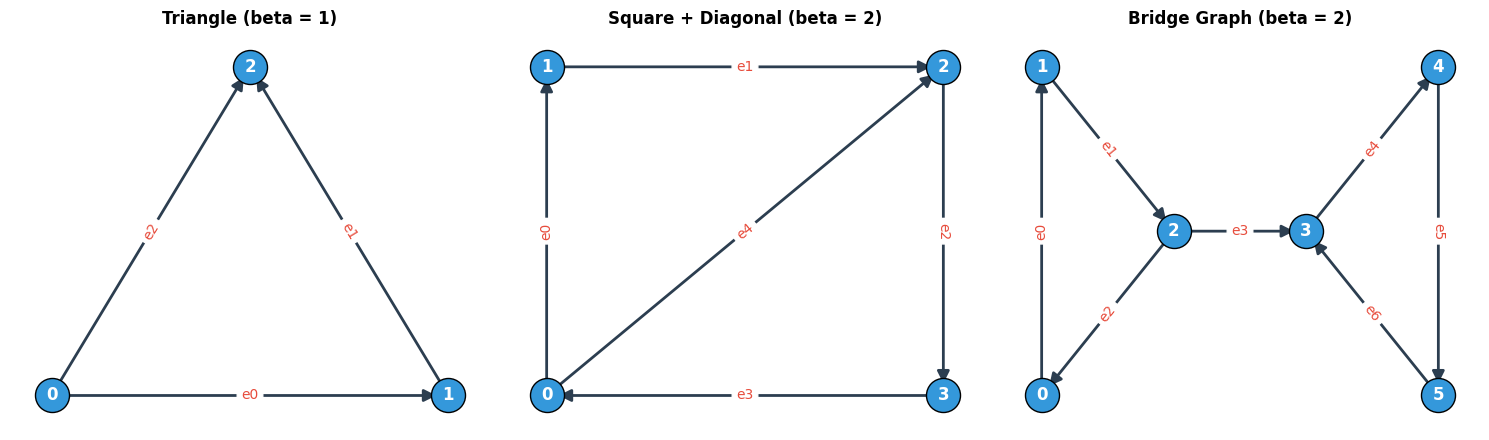

In [3]:
# Construct test graphs
g_triangle = DirectedGraph.triangle(weights=[1, 1, 1])
g_square_diag = DirectedGraph(
    vertices=[0, 1, 2, 3],
    edges=[(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)],
    weights=[1, 1, 1, 1, 1]
)
g_bridge = DirectedGraph(
    vertices=[0, 1, 2, 3, 4, 5],
    edges=[(0, 1), (1, 2), (2, 0), (2, 3), (3, 4), (4, 5), (5, 3)],
    weights=[1, 1, 1, 1, 1, 1, 1]
)

print(f"Triangle:            |V|={len(g_triangle.vertices)}, |E|={len(g_triangle.edges)}, Cycle Rank beta={g_triangle.cycle_rank()}")
print(f"Square with Diag:    |V|={len(g_square_diag.vertices)}, |E|={len(g_square_diag.edges)}, Cycle Rank beta={g_square_diag.cycle_rank()}")
print(f"Bridge Graph:        |V|={len(g_bridge.vertices)}, |E|={len(g_bridge.edges)}, Cycle Rank beta={g_bridge.cycle_rank()}")

# Visualize the three topologies
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

def draw_graph(g, ax, title, layout="planar"):
    G = nx.DiGraph()
    for v in g.vertices:
        G.add_node(v)
    for e in g.edges:
        G.add_edge(e[0], e[1])
    
    if layout == "triangle":
        pos = {0: (0, 0), 1: (2, 0), 2: (1, 1.732)}
    elif layout == "square":
        pos = {0: (0, 0), 1: (0, 2), 2: (2, 2), 3: (2, 0)}
    else:
        pos = {0: (0, 0), 1: (0, 1.5), 2: (1, 0.75), 3: (2, 0.75), 4: (3, 1.5), 5: (3, 0)}

    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#3498db", node_size=600, edgecolors="black")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=12, font_color="white", font_weight="bold")
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#2c3e50", width=2, arrowsize=18, arrowstyle="-|>")
    
    edge_labels = {e: f"e{i}" for i, e in enumerate(g.edges)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax, font_color="#e74c3c", font_size=10)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

draw_graph(g_triangle, axes[0], "Triangle (beta = 1)", layout="triangle")
draw_graph(g_square_diag, axes[1], "Square + Diagonal (beta = 2)", layout="square")
draw_graph(g_bridge, axes[2], "Bridge Graph (beta = 2)", layout="bridge")

plt.tight_layout()
plt.show()

In [4]:
# Coboundary evaluation: (d0 f)(u, v) = f(v) - f(u)
# Assign a potential field to the vertices of the triangle:
f_test = [Fraction(10), Fraction(25), Fraction(40)]
d0_f = g_triangle.d0(f_test)

print("Vertex Potentials f:")
for v, val in enumerate(f_test):
    print(f"  v{v}: {val}")

print("\nInduced Edge Differences d0(f):")
for i, e in enumerate(g_triangle.edges):
    print(f"  e{i} {e}: f({e[1]}) - f({e[0]}) = {f_test[e[1]]} - {f_test[e[0]]} = {d0_f[i]}")

# Verification of exactness: sum around the cycle must vanish
cycle_sum = d0_f[0] + d0_f[1] - d0_f[2]  # e0 + e1 - e2 forms the oriented loop (0->1->2->0)
print(f"\nLoop Holonomy around Triangle (e0 + e1 - e2): {cycle_sum} (identically zero)")
assert cycle_sum == Fraction(0), "Exact coboundary must have vanishing loop sum!"

Vertex Potentials f:
  v0: 10
  v1: 25
  v2: 40

Induced Edge Differences d0(f):
  e0 (0, 1): f(1) - f(0) = 25 - 10 = 15
  e1 (1, 2): f(2) - f(1) = 40 - 25 = 15
  e2 (0, 2): f(2) - f(0) = 40 - 10 = 30

Loop Holonomy around Triangle (e0 + e1 - e2): 0 (identically zero)


## Section 3: The Quotient Space $H^1 = C^1 / B^1$ and Attainment (Theorems L1C-T1 & L1C-T2)

### The First Cohomology Group $Q^1 = C^1 / \text{im } d_0$
Two 1-cochains $\omega_1, \omega_2$ belong to the same equivalence class $[\omega]$ if and only if they differ by an exact gradient:
$$\omega_2 - \omega_1 = d_0 f \iff [\omega_1] = [\omega_2].$$
The **weighted $L^1$ quotient norm** is defined as:
$$\Phi_1([\omega]) = \inf_{f \in C^0} \|\omega + d_0 f\|_{1, \mathbf{w}} = \inf_{f \in C^0} \sum_{e \in E} w_e |\omega_e + f(\text{head}(e)) - f(\text{tail}(e))|.$$

### Key Theorems from Paper 002
- **Theorem L1C-T1 (Attainment):** The infimum is always attained. By fixing the gauge at a reference root vertex $f(v_0) = 0$, the objective function is coercive on the finite-dimensional quotient subspace, guaranteeing an attained minimizer $f^*$.
- **Theorem L1C-T2 (Quotient Norm):** $\Phi_1$ is a genuine norm on $Q^1$. In particular:
  $$\Phi_1([\omega]) = 0 \iff \omega \in \text{im } d_0 \quad (\omega \text{ is exact}).$$
  **Zero-Weight Refusal:** This theorem strictly requires $w_e > 0$ for all edges. If any edge had $w_e = 0$, an obstruction residing on that edge would have zero cost, collapsing the norm into a pseudonorm. The software strictly refuses zero edge weights (`ZeroWeightRefusalError`).

In [5]:
# Verify Theorem L1C-T1 and L1C-T2 on Triangle graph
# 1. Exact cochain (omega = d0 f):
f_exact = [Fraction(0), Fraction(5), Fraction(12)]
omega_exact = g_triangle.d0(f_exact)
receipt_exact = L1QuotientSolver.solve(g_triangle, omega_exact)

print(f"Exact Cochain omega:      {[float(x) for x in omega_exact]}")
print(f"Optimal L1 Residual r*:   {[float(x) for x in receipt_exact.primal_residual]}")
print(f"Quotient Norm Phi1:       {receipt_exact.primal_norm}")
print(f"Diagnostic Type:          {receipt_exact.diagnostic_type} (Phi1 == 0)")
assert receipt_exact.primal_norm == Fraction(0)
assert receipt_exact.diagnostic_type == "ExactRepair"

# 2. Obstructed cochain with loop flux:
omega_obstructed = [Fraction(2), Fraction(3), Fraction(-4)]
# Loop flux = 2 + 3 - (-4) = 9
receipt_obstr = L1QuotientSolver.solve(g_triangle, omega_obstructed)
print(f"\nObstructed Cochain omega: {[float(x) for x in omega_obstructed]}")
print(f"Optimal Potential f*:     {[float(x) for x in receipt_obstr.primal_potential]}")
print(f"Optimal Residual r*:      {[float(x) for x in receipt_obstr.primal_residual]}")
print(f"Quotient Norm Phi1:       {receipt_obstr.primal_norm}")
print(f"Diagnostic Type:          {receipt_obstr.diagnostic_type} (Phi1 > 0)")
assert receipt_obstr.primal_norm > Fraction(0)
assert receipt_obstr.diagnostic_type == "ClosedResidual"

# 3. Defensive Check: Zero-Weight Refusal Law
try:
    g_bad = DirectedGraph(vertices=[0, 1], edges=[(0, 1)], weights=[0])
    print("[FAIL] Zero weight was accepted!")
except ZeroWeightRefusalError as e:
    print(f"\n[DEFENSE VERIFIED] Zero-weight input successfully refused per L1C-T2:\n  {e}")

Exact Cochain omega:      [5.0, 7.0, 12.0]
Optimal L1 Residual r*:   [0.0, 0.0, 0.0]
Quotient Norm Phi1:       0
Diagnostic Type:          ExactRepair (Phi1 == 0)

Obstructed Cochain omega: [2.0, 3.0, -4.0]
Optimal Potential f*:     [0.0, 7.0, 4.0]
Optimal Residual r*:      [9.0, 0.0, 0.0]
Quotient Norm Phi1:       9
Diagnostic Type:          ClosedResidual (Phi1 > 0)

[DEFENSE VERIFIED] Zero-weight input successfully refused per L1C-T2:
  [L1_COHOMOLOGY_ERROR] Edge (0, 1) has zero weight; strictly positive weights required by L1C-T2


## Section 4: Interactive Sandbox & Defect Injection

In this section, we study how L1 cohomology behaves under deliberate **defect injection** on the Square with Diagonal graph ($n=4, m=5, \beta=2$).
The two independent cycles are:
1. Cycle 1: $e_0 (0\to 1) + e_1 (1\to 2) - e_4 (0\to 2)$ (lower-left triangle).
2. Cycle 2: $e_4 (0\to 2) + e_2 (2\to 3) + e_3 (3\to 0)$ (upper-right triangle).

We compare three scenarios:
- **Scenario A (Clean Gauge):** Injected cochain is pure gradient noise $\omega = d_0 f$.
- **Scenario B (Single Cycle Defect):** Topological flux injected around Cycle 1 only.
- **Scenario C (Double Cycle Defect):** Flux injected across both cycles.

Notice how the basic feasible solution isolates the topological defect onto at most $\beta = 2$ edges (Theorem L1C-T5: every quotient class admits an optimum with $|\text{supp}(\mathbf{r}^*)| \le \beta$).

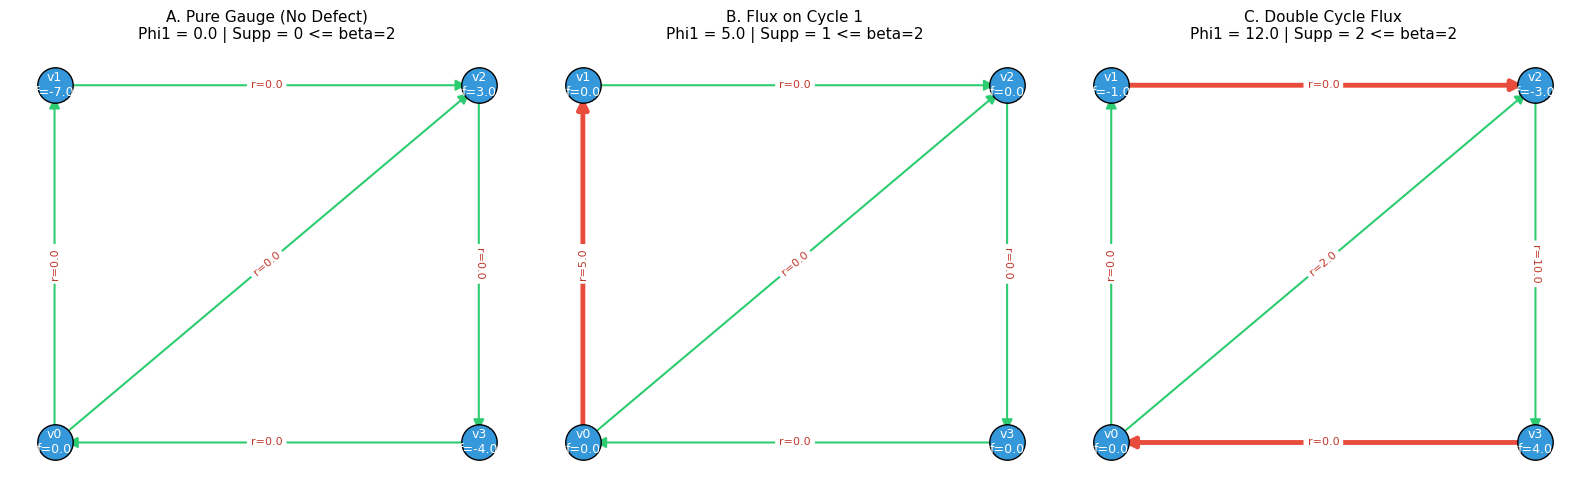

In [6]:
# Run Defect Injection Experiments on Square + Diagonal Graph
scenarios = [
    ("A. Pure Gauge (No Defect)", g_square_diag.d0([0, 7, -3, 4])),
    ("B. Flux on Cycle 1", [5, 0, 0, 0, 0]),
    ("C. Double Cycle Flux", [1, 2, 3, 4, 5]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pos = {0: (0, 0), 1: (0, 2), 2: (2, 2), 3: (2, 0)}

for idx, (name, omega_input) in enumerate(scenarios):
    receipt = L1QuotientSolver.solve(g_square_diag, omega_input)
    r_vals = [float(x) for x in receipt.primal_residual]
    f_vals = [float(x) for x in receipt.primal_potential]
    
    ax = axes[idx]
    G = nx.DiGraph()
    for v in g_square_diag.vertices:
        G.add_node(v)
    for e in g_square_diag.edges:
        G.add_edge(e[0], e[1])
        
    # Color nodes by potential f*
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#3498db", node_size=650, edgecolors="black")
    node_labels = {v: f"v{v}\nf={f_vals[v]:.1f}" for v in g_square_diag.vertices}
    nx.draw_networkx_labels(G, pos, labels=node_labels, ax=ax, font_size=9, font_color="white")
    
    # Color edges: red if r* != 0 (defect), green if r* == 0 (cleanly repaired)
    edge_colors = ["#e74c3c" if abs(r) > 1e-5 else "#2ecc71" for r in r_vals]
    edge_widths = [3.5 if abs(r) > 1e-5 else 1.5 for r in r_vals]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=edge_widths, arrowsize=16, arrowstyle="-|>")
    
    edge_labels = {e: f"r={r_vals[i]:.1f}" for i, e in enumerate(g_square_diag.edges)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax, font_size=8, font_color="#c0392b")
    
    ax.set_title(f"{name}\nPhi1 = {float(receipt.primal_norm):.1f} | Supp = {receipt.support_size} <= beta={receipt.cycle_rank}", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Section 5: Discrete Bianchi Nilpotency (Theorem L1C-T7)

Moving beyond 1-dimensional networks, consider a **simplicial 2-complex** $K = (V, E, F)$, where 2-cells are oriented triangular faces:
- Boundary $D_1: C_1 \to C_0$ maps edges to endpoints.
- Boundary $D_2: C_2 \to C_1$ maps faces to their oriented boundary loops.
- Coboundary $d_0 = D_1^\top: C^0 \to C^1$ computes the gradient of vertex potentials.
- Coboundary $d_1 = D_2^\top: C^1 \to C^2$ computes the **discrete curl** (field strength / curvature) through each face.

### The Discrete Bianchi Identity
In continuum differential geometry and gauge theory, the Bianchi identity states that the exterior derivative is nilpotent: $d^2 = d \circ d = 0$.
In discrete lattice gauge theory:
- Let $\phi \in C^0$ be an arbitrary vertex potential.
- The pure gauge connection is $A = d_0 \phi$.
- The field strength is $F = d_1 A = d_1 (d_0 \phi)$.
Because $d_1 d_0 = (D_1 D_2)^\top$ and $D_1 D_2 = 0$ identically:
$$d_1(d_0 \phi) = 0 \quad \forall \phi \in C^0.$$

Let us verify this identity over arbitrary rational potentials using `Simplicial2Complex`.

In [7]:
# Construct a Simplicial 2-Complex of two triangles glued along an edge (0, 2):
# Faces: f0 = (0, 1, 2) and f1 = (0, 2, 3)
sc2 = Simplicial2Complex(
    vertices=[0, 1, 2, 3],
    edges=[(0, 1), (1, 2), (0, 2), (2, 3), (0, 3)],
    faces=[(0, 1, 2), (0, 2, 3)],
    weights=[1, 1, 1, 1, 1]
)

print(f"Simplicial Complex initialized: |V|={len(sc2.vertices)}, |E|={len(sc2.edges)}, |F|={len(sc2.faces)}")
print(f"Topological nilpotency D1 @ D2 == 0: {sc2.verify_nilpotency()}")

# Test Bianchi identity with arbitrary rational vertex potential
phi_arbitrary = [Fraction(13, 7), Fraction(-22, 5), Fraction(101, 3), Fraction(42, 1)]
d0_phi = sc2.d0(phi_arbitrary)
d1_d0_phi = sc2.discrete_bianchi_identity(phi_arbitrary)

print("\nArbitrary Potential phi:")
print(f"  phi = {[str(x) for x in phi_arbitrary]}")
print("\nGauge Connection A = d0(phi):")
print(f"  A = {[str(x) for x in d0_phi]}")
print("\nField Strength F = d1(d0 phi):")
print(f"  F = {[str(x) for x in d1_d0_phi]} (identically zero on all faces)")

assert all(x == Fraction(0) for x in d1_d0_phi), "Bianchi identity violated!"
print("\n[OK] Discrete Bianchi Nilpotency (Theorem L1C-T7) verified over exact rationals.")

Simplicial Complex initialized: |V|=4, |E|=5, |F|=2
Topological nilpotency D1 @ D2 == 0: True

Arbitrary Potential phi:
  phi = ['13/7', '-22/5', '101/3', '42']

Gauge Connection A = d0(phi):
  A = ['-219/35', '571/15', '668/21', '25/3', '281/7']

Field Strength F = d1(d0 phi):
  F = ['0', '0'] (identically zero on all faces)

[OK] Discrete Bianchi Nilpotency (Theorem L1C-T7) verified over exact rationals.


## Section 6: Quantum Coherence and Phase Lifts

For a density matrix $\rho$, extract phases only on $E_\rho=\{(u,v):\rho_{uv}\ne0\}$. With $(d_0\theta)_{uv}=\theta_v-\theta_u$, diagonal conjugation by $U_\theta=\operatorname{diag}(e^{-i\theta_v})$ adds $d_0\theta$ to a chosen phase lift. A lift that is a real gradient can be removed by the corresponding opposite potential.

The real quotient norm of a chosen lift is invariant under real gradients. Re-extracting principal arguments can add $2\pi$ edge periods, changing that real norm. Branch-independent multiplicative holonomy uses integral cycles on the support graph; real circulations are used for the LP dual. Minimizing also over integer edge periods defines a quotient-group distance, not a real norm.

For a fixed state, trace distance to its diagonal is bounded by $\sum_{u<v}|\rho_{uv}|$. This is a static inequality; it is not a dynamical claim about surviving coherence under environmental dephasing. The example checks Hermiticity, unit trace, and exact rational PSD via $LDL^\dagger$. Coherence is exact for rational complex moduli and binary64 otherwise.


In [8]:
# Construct an exact rational pure quantum state |psi> across 3 vertices:
# |psi> = 1/3 |0> + 2/3 |1> + 2/3 |2>
# Norm squared = (1/9) + (4/9) + (4/9) = 9/9 = 1.
psi_amplitudes = [
    RationalComplex(Fraction(1, 3), Fraction(0)),
    RationalComplex(Fraction(2, 3), Fraction(0)),
    RationalComplex(Fraction(2, 3), Fraction(0))
]

rho = QuantumDensityMatrix.pure_state(psi_amplitudes)
rho.validate_state()
print("Quantum Density Matrix rho = |psi><psi| (exact LDL^dagger PSD certified):")
for j in range(rho.dim):
    row_str = [f"{rho.matrix[j][k].re}" for k in range(rho.dim)]
    print(f"  Row {j}: [{', '.join(row_str)}]")

# Compute dephased diagonal pointer state
rho_diag = rho.dephased_state()
off_diag_coherence = rho.off_diagonal_l1_coherence()

print(f"\nTotal Off-Diagonal L1 Coherence: {off_diag_coherence} = {float(off_diag_coherence):.4f}")
print(f"Trace Normalization Tr(rho):     {sum(rho.matrix[j][j].re for j in range(rho.dim))}")

# Check that 2x2 principal minors are strictly satisfied: rho_jj * rho_kk >= |rho_jk|^2
minors_ok = True
for j in range(rho.dim):
    for k in range(j + 1, rho.dim):
        diag_prod = rho.matrix[j][j].re * rho.matrix[k][k].re
        off_sq = rho.matrix[j][k].norm_sq()
        assert diag_prod >= off_sq, f"Principal minor violated at ({j}, {k})"
print(f"All 2x2 Principal Minors Satisfied: {minors_ok}")
print("[OK] Quantum integrity checks and trace bounds verified.")

Quantum Density Matrix rho = |psi><psi| (exact LDL^dagger PSD certified):
  Row 0: [1/9, 2/9, 2/9]
  Row 1: [2/9, 4/9, 4/9]
  Row 2: [2/9, 4/9, 4/9]

Total Off-Diagonal L1 Coherence: 8/9 = 0.8889
Trace Normalization Tr(rho):     1
All 2x2 Principal Minors Satisfied: True
[OK] Quantum integrity checks and trace bounds verified.


## Summary & Claim Hygiene Discipline

In this conceptual track notebook, we have demonstrated:
1. **L1 vs L2 Localization:** While L2 Hodge projection smears defects globally across every edge of the network, L1 quotient minimization always admits an optimal representative with support bounded by the cycle rank $\beta$ (Theorem L1C-T5).
2. **Attainment:** The finite quotient infimum $\Phi_1([\omega])$ is always attained by an exact potential (Theorem L1C-T1).
3. **Discrete Bianchi Nilpotency:** The discrete exterior derivative is nilpotent ($d_1(d_0 \phi) = 0$, Theorem L1C-T7).
4. **Quantum Phase Holonomy:** Chosen phase-lift defects are separated from integral-cycle holonomy and static coherence bounds.

### Claim Fences (`RULE[user_global]`)
- **What this notebook supports:** Demonstrates in this finite graph model that L1 quotient minimization isolates topological obstructions onto minimal supports, certifies them via dual circulations, and preserves exact rational nilpotency.
- **What this notebook does NOT support:** It does not claim an L1 Hodge decomposition for continuous manifolds, does not claim universal physical selection of L1 norms, and does not claim infinite-dimensional extensions.
- **Narrowest defensible claim:** For finite directed graphs with positive rational weights, the L1 quotient infimum is attained, computes a true quotient norm, and admits an optimal representative with support at most $\beta$.
- **Next test needed:** Testing the exact two-phase simplex tableau steps, zero duality gap complementary slackness certificates, and Lean 4 formal mechanization in `002_formal_l1_cohomology.ipynb`.